
# Cohort Retention Analysis

###  Project Overview

This notebook analyzes monthly user retention using a synthetic multi-month activity dataset.

The objective is to identify how user engagement changes over time across acquisition cohorts and evaluate retention patterns using cohort analysis.

###  Dataset

- Source: `data/cohort_activity.csv`
- Dataset type: Synthetic user activity data
- Unique users: 1,200
- Activity records: 3,016
- Acquisition period: January–June 2024
- Activity observation period: January–July 2024

###  Analysis Objectives

1. Identify monthly acquisition cohorts.
2. Calculate months since acquisition.
3. Measure monthly active users.
4. Construct a cohort retention matrix.
5. Visualize retention patterns using a heatmap.
6. Derive actionable business insights.


In [3]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load cohort activity dataset
csv_path = Path('../data/cohort_activity.csv')

if not csv_path.exists():
    raise FileNotFoundError(f"Dataset not found: {csv_path.resolve()}")

df_cohort = pd.read_csv(csv_path)

# Convert activity_date to datetime
df_cohort['activity_date'] = pd.to_datetime(
    df_cohort['activity_date']
)

print(f"Dataset loaded: {len(df_cohort):,} records")
print(f"Unique users: {df_cohort['user_id'].nunique():,}")

df_cohort.head()


Dataset loaded: 3,016 records
Unique users: 1,200


,user_id,activity_date,activity_month,acquisition_month,cohort_index
0,USR_0001,2024-02-15,2024-02-01,2024-02-01,0
1,USR_0001,2024-05-19,2024-05-01,2024-02-01,3
2,USR_0001,2024-06-11,2024-06-01,2024-02-01,4
3,USR_0002,2024-03-24,2024-03-01,2024-03-01,0
4,USR_0002,2024-05-24,2024-05-01,2024-03-01,2



### Cohort Retention Analysis

Calculate the number of unique active users for each acquisition cohort and each subsequent month.

Compare monthly active users against the original cohort size to calculate retention percentages.


In [5]:

# Count unique active users by acquisition cohort and cohort index

cohort_data = (
    df_cohort
    .groupby(['acquisition_month', 'cohort_index'])['user_id']
    .nunique()
    .unstack()
)

cohort_data


cohort_index,0,1,2,3,4,5,6
acquisition_month,,,,,,,
2024-01-01,290.0,139.0,115.0,97.0,94.0,82.0,77.0
2024-02-01,233.0,108.0,101.0,85.0,74.0,57.0,NaN
2024-03-01,252.0,128.0,92.0,88.0,79.0,NaN,NaN
2024-04-01,172.0,88.0,71.0,59.0,NaN,NaN,NaN
2024-05-01,130.0,64.0,54.0,NaN,NaN,NaN,NaN
2024-06-01,123.0,64.0,NaN,NaN,NaN,NaN,NaN


In [6]:
# Calculate cohort retention percentages

cohort_sizes = cohort_data[0]

retention_matrix = cohort_data.divide(
    cohort_sizes,
    axis=0
) * 100

retention_matrix.round(2)

cohort_index,0,1,2,3,4,5,6
acquisition_month,,,,,,,
2024-01-01,100.0,47.93,39.66,33.45,32.41,28.28,26.55
2024-02-01,100.0,46.35,43.35,36.48,31.76,24.46,NaN
2024-03-01,100.0,50.79,36.51,34.92,31.35,NaN,NaN
2024-04-01,100.0,51.16,41.28,34.30,NaN,NaN,NaN
2024-05-01,100.0,49.23,41.54,NaN,NaN,NaN,NaN
2024-06-01,100.0,52.03,NaN,NaN,NaN,NaN,NaN



### Cohort Retention Heatmap

Visualize monthly retention percentages across acquisition cohorts.

The heatmap highlights differences in retention across cohorts and identifies the stages where user engagement declines.


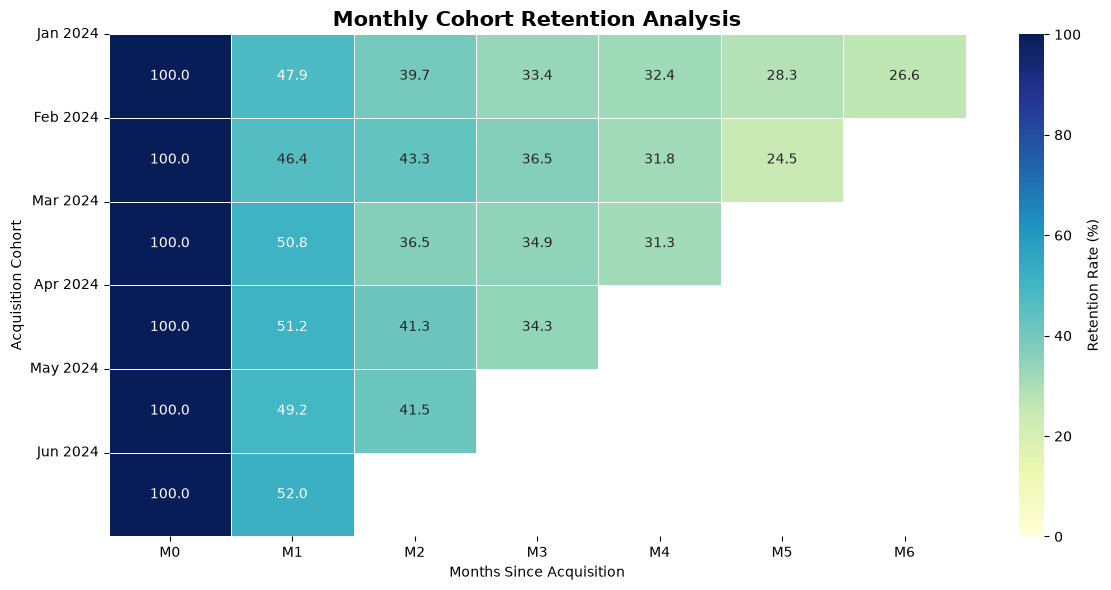

In [8]:

# Plot cohort retention heatmap

plt.figure(figsize=(12, 6))

sns.heatmap(
    retention_matrix,
    annot=True,
    fmt='.1f',
    cmap='YlGnBu',
    linewidths=0.5,
    vmin=0,
    vmax=100,
    cbar_kws={'label': 'Retention Rate (%)'}
)

plt.title('Monthly Cohort Retention Analysis', fontsize=15, weight='bold')
plt.xlabel('Months Since Acquisition')
plt.ylabel('Acquisition Cohort')

plt.xticks(
    ticks=np.arange(len(retention_matrix.columns)) + 0.5,
    labels=[f'M{i}' for i in retention_matrix.columns]
)

# Format acquisition cohort labels as Month Year
cohort_labels = [
    pd.to_datetime(label).strftime('%b %Y')
    for label in retention_matrix.index
]

plt.yticks(
    ticks=np.arange(len(cohort_labels)),
    labels=cohort_labels,
    rotation=0
)

plt.tight_layout()
plt.show()


### Business Insights and Interpretation

The cohort retention analysis reveals a consistent decline in user activity after acquisition. 
Although all cohorts begin with 100% activity in Month 0, retention drops to approximately 46–52% by Month 1.

The following observations highlight the key retention patterns across acquisition cohorts.


### Key Observations

- **Significant Early Drop-off:** Retention falls from 100% in Month 0 to approximately 46–52% in Month 1, indicating that nearly half of acquired users do not return in the following month.

- **Continued Decline:** By Month 2, retention ranges between 36.5% and 43.3% across cohorts.

- **Gradual Stabilization:** The January cohort retains 26.6% of its original users by Month 6, suggesting that a smaller group of users continues to remain active over time.

- **Cohort Consistency:** Month 1 retention is relatively similar across all six cohorts, ranging from 46.4% to 52.0%. No substantial difference in early retention is evident.

### Business Recommendations

1. **Improve Onboarding:** Introduce guided onboarding experiences to encourage users to return after their initial interaction.

2. **Strengthen Early Engagement:** Use targeted email campaigns, personalized recommendations, and timely reminders during the first month.

3. **Investigate Retention Drivers:** Analyze user behavior to identify the activities and features associated with repeat engagement.

4. **Monitor Long-Term Retention:** Track cohort retention over multiple months to evaluate whether engagement initiatives improve customer retention.

### Analytical Limitation

This analysis uses synthetically generated activity data. The observed retention patterns demonstrate cohort analysis techniques but should not be interpreted as actual customer behavior or evidence of real business performance.